# Attention methods: raw image to fresh explanations

This walkthrough runs one pretrained ViT on one raw image. It computes Raw, Grad-CAM, ATTATTR, Rollout, TAM, Beyond-H/C, generic Relevance and genuine Chefer DTD/LRP. No saved measurement is read. No probe training is needed.

Install `pip install "vlmprobe[transformers,visualization,notebooks]"`. GPU recommended; CPU works but integration takes longer. Set `VLM_PROBING_MODEL` to a local ViT checkpoint and `VLM_PROBING_DEVICE` to choose a device. The default downloads the pretrained checkpoint and a public raw COCO image.

## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

New Colab checkouts use the reviewed source **gexinh/vlm-probe** at commit
`e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1`. This pins the runtime source for
reproducible execution.

Optional environment settings: VLM_PROBING_REPOSITORY and VLM_PROBING_REF
override that pinned repository and commit; VLM_PROBING_COLAB_DIR changes
the checkout directory (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "gexinh/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get(
        "VLM_PROBING_REF", "e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1"
    )
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


## 1. Load the model and prepare the actual image

The classifier has no text prompt. We choose its top class once, then keep that target fixed for every gradient or input-path calculation. The displayed background is reconstructed from the processed pixels so its geometry matches the patch grid.

In [1]:
from pathlib import Path
import os
from io import BytesIO
from urllib.request import urlopen
import numpy as np
import torch
from PIL import Image
from transformers import AutoImageProcessor, ViTForImageClassification
from vlmprobe import Prober, ClassScore
from vlmprobe import visualization as viz
import matplotlib.pyplot as plt

# Install: pip install "vlmprobe[transformers,visualization]"
# Set VLM_PROBING_MODEL to a local directory to avoid downloading this checkpoint.
model_id = os.environ.get("VLM_PROBING_MODEL", "google/vit-base-patch16-224")
device = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
model = ViTForImageClassification.from_pretrained(model_id, attn_implementation="eager").to(device).eval()
processor = AutoImageProcessor.from_pretrained(os.environ.get("VLM_PROBING_PROCESSOR", model_id))
probe = Prober(model, processor)

# A raw COCO image, not a saved attention map or a previous model result.
image_path = os.environ.get("VLM_PROBING_IMAGE")
image = (Image.open(image_path) if image_path else Image.open(BytesIO(urlopen(
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png"
).read()))).convert("RGB")
inputs = {k: v.to(device) for k, v in processor(images=image, return_tensors="pt").items()}
with torch.no_grad():
    logits = model(**inputs).logits
    target_id = int(logits[0].argmax())  # Choose once; keep fixed during attribution.
metric = ClassScore(target_id, kind="logit")
print("Fixed target:", target_id, model.config.id2label.get(target_id))

# Plot the actual processed image; its crop/resize aligns with the patch tokens.
mean = torch.tensor(processor.image_mean)[:, None, None]
std = torch.tensor(processor.image_std)[:, None, None]
rgb = (inputs["pixel_values"][0].detach().cpu() * std + mean).clamp(0, 1)
processed_image = Image.fromarray((rgb.permute(1, 2, 0).numpy() * 255).astype("uint8"))
patch = model.config.patch_size
grid_shape = tuple(int(n // patch) for n in inputs["pixel_values"].shape[-2:])
visual_positions = list(range(1, 1 + grid_shape[0] * grid_shape[1]))  # CLS is 0.
last = probe.describe()["methods"]["attention.profile"]["sites"][-1]
output_dir = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/attention-tutorial"))
output_dir.mkdir(parents=True, exist_ok=True)


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


Fixed target: 285 Egyptian cat


## 2. Compute each explanation

Eight integration samples keep this demonstration short. Increase `VLM_PROBING_STEPS` (for example, 20 or 64) and inspect convergence for analysis. ATTATTR integrates one layer in attention space; TAM and Beyond integrate pixels. The default zero baseline is in normalized processed-image coordinates.

Grad-CAM {'cam': (1, 1, 197, 197), 'head_weights': (1, 1, 12, 197), 'query_mask': (1, 197), 'key_mask': (1, 197), 'baseline_score': (1,)}
ATTATTR {'attribution': (1, 1, 12, 197, 197), 'head_attribution': (1, 1, 12), 'token_attribution': (1, 1, 197, 197), 'query_mask': (1, 197), 'key_mask': (1, 197), 'baseline_score': (1,)}
TAM {'relevance': (1, 197, 197), 'state': (1, 197, 197), 'feedback': (1, 197, 197), 'map': (1, 197, 197), 'query_mask': (1, 197), 'key_mask': (1, 197), 'baseline_score': (1,)}
Beyond-H {'relevance': (1, 197, 197), 'perception': (1, 197, 197), 'feedback': (1, 197, 197), 'layer_perception': (12, 1, 197, 197), 'head_weights': (12, 1, 12), 'map': (1, 197, 197), 'query_mask': (1, 197), 'key_mask': (1, 197), 'baseline_score': (1,)}
Beyond-C {'relevance': (1, 197, 197), 'perception': (1, 197, 197), 'feedback': (1, 197, 197), 'layer_perception': (12, 1, 197, 197), 'token_weights': (12, 1, 197), 'map': (1, 197, 197), 'query_mask': (1, 197), 'key_mask': (1, 197), 'baseline_sco

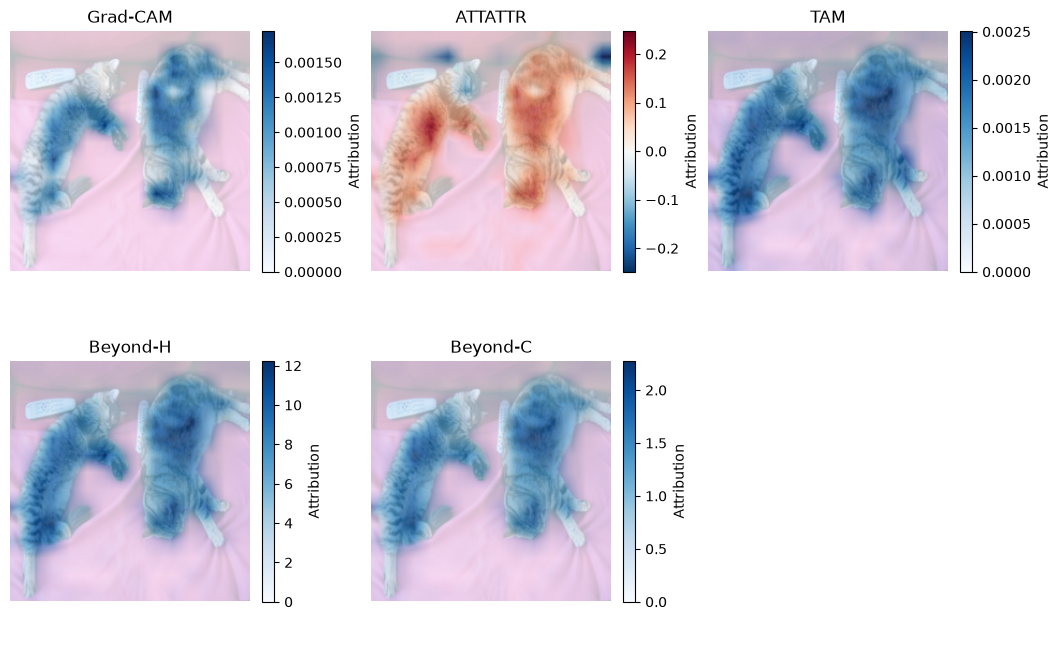

In [2]:
steps = int(os.environ.get("VLM_PROBING_STEPS", "8"))
# 8 samples keep the walkthrough short; use 20+ and check convergence for analysis.
results = {
    "Grad-CAM": probe.attention.grad_cam(layers=[last], queries=[0], keys="visual").run(inputs, metric=metric),
    "ATTATTR": probe.attention.attribution(layers=[last], queries=[0], keys="visual", steps=steps).run(inputs, metric=metric),
    "TAM": probe.attention.tam(queries=[0], keys="visual", steps=steps, residual_normalize=True).run(inputs, metric=metric),
    "Beyond-H": probe.attention.beyond_intuition(variant="head", queries=[0], keys="visual", steps=steps).run(inputs, metric=metric),
    "Beyond-C": probe.attention.beyond_intuition(variant="token", queries=[0], keys="visual", steps=steps).run(inputs, metric=metric),
}
for name, result in results.items():
    print(name, {key: tuple(value.shape) for key, value in result.tensors.items()})
    result.save(output_dir / name.lower())
fig, axes = viz.plot_attention_comparison(
    processed_image, results, grid_shape=grid_shape,
    visual_positions=visual_positions, query_positions=[0], columns=3,
    signed={name: name == "ATTATTR" for name in results},
    shared_scale=False, image_alpha=0.25, alpha=1.0,
)
fig.savefig(output_dir / "attention-maps.png", dpi=160, bbox_inches="tight")
plt.show()


## 3. Add raw attention, propagated maps and genuine DTD/LRP

These methods have different units; we use individual color scales. A zero Grad-CAM is displayed as a measured zero, not replaced by another method. Missing capabilities raise an error instead of showing a fake map.

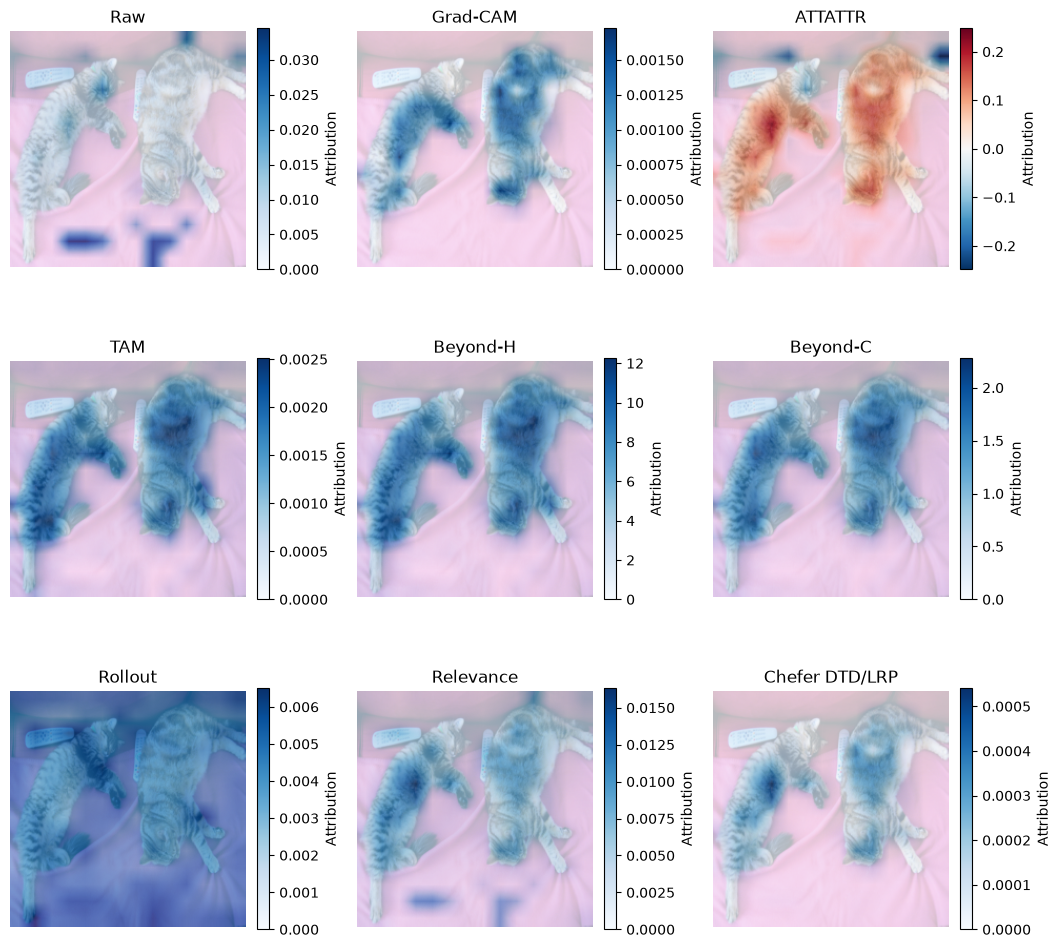

Raw range 0.0003601920325309038 0.034532900899648666 nonzero 196
Grad-CAM range 0.0 0.001727947499603033 nonzero 69
ATTATTR range -0.24844041466712952 0.22324958443641663 nonzero 196
TAM range 1.5777932276250795e-05 0.0025109711568802595 nonzero 196
Beyond-H range 0.06270604580640793 12.258661270141602 nonzero 196
Beyond-C range 0.007400038186460733 2.2792201042175293 nonzero 196
Rollout range 0.0030146860517561436 0.006505122408270836 nonzero 196
Relevance range 0.0009147031232714653 0.016321439296007156 nonzero 196
Chefer DTD/LRP range 2.530006895540282e-06 0.0005407657590694726 nonzero 196


In [3]:
raw = probe.attention.profile(layers=[last], queries=[0], include_attention=True).run(inputs)
rollout = probe.attention.rollout().run(inputs)
relevance = probe.attention.relevance().run(inputs, metric=metric)
chefer = probe.attention.dtd_lrp().run(inputs["pixel_values"], target=target_id)
torch.testing.assert_close(chefer.tensors["logits"], logits.cpu(), rtol=1e-4, atol=1e-4)
# Extract explicit coordinates because raw and propagated maps have different schemas.
named_maps = {"Raw": raw.tensors["attention"][0, 0, :, 0, 1:].mean(0).reshape(grid_shape)}
for name, result in results.items():
    field = "cam" if name == "Grad-CAM" else "token_attribution" if name == "ATTATTR" else "map"
    tensor = result.tensors[field]
    if tensor.ndim == 4:
        tensor = tensor[-1]
    named_maps[name] = tensor[0, 0, 1:].reshape(grid_shape)
named_maps.update({
    "Rollout": rollout.tensors["rollout"][0, 0, 1:].reshape(grid_shape),
    "Relevance": relevance.tensors["relevance"][0, 0, 1:].reshape(grid_shape),
    "Chefer DTD/LRP": chefer.tensors["patch_relevance"][0],
})
fig, axes = viz.plot_attention_comparison(processed_image, named_maps, columns=3,
    signed={name: bool((values < 0).any()) for name, values in named_maps.items()},
    shared_scale=False, image_alpha=0.25, alpha=1.0)
fig.savefig(output_dir / "all-attention-methods.png", dpi=160, bbox_inches="tight")
plt.show()
for name, values in named_maps.items():
    print(name, "range", float(values.min()), float(values.max()), "nonzero", int(values.count_nonzero()))


## Interpretation

Raw attention and Rollout are target-independent descriptions. Gradient/Relevance methods depend on the chosen target and approximation. DTD/LRP uses copied classifier weights and author propagation rules, not only an attention-gradient product. None of these heatmaps proves a causal circuit; use the separate knockout walkthrough to measure answer changes. [Method parameters and citations](../docs/methods/attention_maps.md).